# 02 – Les communes et la table commune × jour

## Leçon 1 – Ce qu'on construit

Comme dans le projet 13 : **une ligne = une commune × un jour**, et une colonne cible `feu` = 1 s'il y a eu au moins un départ de feu ce jour-là dans cette commune.

Nouveautés à cette échelle :
1. **3 505 communes × 3 653 jours ≈ 12,8 millions de lignes**. Un CSV de cette taille ferait plusieurs Go et mettrait une minute à lire → on passe au format **Parquet**.
2. Des **communes ont fusionné** depuis 2016 : certains feux portent un code INSEE qui n'existe plus. Il faut les rattacher à leur commune actuelle.
3. On récupère aussi les **contours** des communes (pour les cartes) et leur **population** (les feux sont allumés par des humains).

In [1]:
import pandas as pd
import numpy as np
import requests
import geopandas as gpd

DEPTS = ["04", "05", "06", "07", "11", "13", "26", "2A", "2B", "30", "34", "48", "66", "83", "84"]

## Étape 1 – La liste des communes (geo.api.gouv.fr)

Même API que pour le projet 13, mais on boucle sur les 15 départements. On demande en plus :
- `population` : nombre d'habitants ;
- `surface` : superficie en **hectares**.

In [2]:
lignes = []
for dept in DEPTS:
    url = f"https://geo.api.gouv.fr/departements/{dept}/communes?fields=nom,code,centre,population,surface"
    r = requests.get(url, timeout=60)
    r.raise_for_status()
    for c in r.json():
        lignes.append({
            "code": c["code"], "nom": c["nom"], "dept": dept,
            "lon": c["centre"]["coordinates"][0], "lat": c["centre"]["coordinates"][1],
            "population": c.get("population", 0), "surface_ha": c.get("surface"),
        })

communes = pd.DataFrame(lignes)
communes["densite"] = communes["population"] / (communes["surface_ha"] / 100)   # habitants / km²
print(communes.shape)   # attendu : (3505, 8)
communes.groupby("dept").size()

(3505, 8)


dept
04    198
05    162
06    163
07    335
11    433
13    119
26    362
2A    124
2B    236
30    350
34    341
48    152
66    226
83    153
84    151
dtype: int64

**Attendu :** 3 505 communes, de 119 (Bouches-du-Rhône) à 433 (Aude).

`densite` : 1 km² = 100 ha, donc on divise la surface en ha par 100. La densité va de quasiment 0 (villages de Lozère) à plusieurs milliers d'habitants/km² (Nice, Marseille).

In [3]:
communes["densite"].describe().round(1)

count    3505.0
mean      120.9
std       316.8
min         0.2
25%         9.3
50%        31.5
75%       107.6
max      5448.8
Name: densite, dtype: float64

## Étape 2 – Les feux et le problème des communes fusionnées

Depuis 2016, des centaines de communes françaises ont fusionné en **communes nouvelles**. Exemple : *Dio-et-Valquières* (34093) fait désormais partie de *Lunas* (34144). La BDIFF garde parfois l'ancien code.

L'API fournit la table de correspondance `communes_associees_deleguees` : pour chaque ancienne commune, son `chefLieu` (code de la commune nouvelle).

In [4]:
df = pd.read_csv("../data/raw/Incendies.csv", sep=";", skiprows=3, encoding="utf-8",
                 dtype={"Département": str, "Code INSEE": str})
feux = df[df["Département"].isin(DEPTS)].copy()
feux["date"] = pd.to_datetime(feux["Date de première alerte"])

connu = feux["Code INSEE"].isin(communes["code"])
print(f"Codes reconnus directement : {connu.mean():.2%}  ({(~connu).sum()} feux à rattacher)")

Codes reconnus directement : 99.47%  (86 feux à rattacher)


In [5]:
anciennes = pd.DataFrame(requests.get(
    "https://geo.api.gouv.fr/communes_associees_deleguees?fields=code,nom,chefLieu", timeout=120
).json())
vers_nouvelle = dict(zip(anciennes["code"], anciennes["chefLieu"]))
print(len(anciennes), "anciennes communes dans la table de correspondance (toute la France)")

# si le code est connu on le garde, sinon on le traduit
feux["code"] = feux["Code INSEE"].where(connu, feux["Code INSEE"].map(vers_nouvelle))

perdus = ~feux["code"].isin(communes["code"])
print(f"Feux rattachés : {(~perdus).mean():.2%}  — perdus : {perdus.sum()}")

2576 anciennes communes dans la table de correspondance (toute la France)
Feux rattachés : 99.86%  — perdus : 23


**Attendu :** 63 feux rattachés grâce à la correspondance, **23 feux perdus** (0,14 %). Ce sont des communes fusionnées il y a longtemps que l'API ne connaît plus.

> Décision de data analyst : 23 feux sur 16 162, on les **écarte** et on le **documente**. Chercher à les récupérer à la main coûterait des heures pour un effet invisible sur le modèle. Il faut savoir quand s'arrêter !

In [6]:
feux = feux[~perdus]
feux.to_csv("../data/processed/feux_med.csv", index=False)
print(len(feux))   # attendu : 16139

16139


## Étape 3 – La cible : un feu par commune × jour

Plusieurs départs de feu peuvent avoir lieu le même jour dans la même commune. Notre cible est *« au moins un feu »* → on dédoublonne les couples (commune, jour).

In [7]:
feux["jour"] = feux["date"].dt.normalize()
jours_feu = feux[["code", "jour"]].drop_duplicates()
jours_feu["feu"] = 1
print(len(jours_feu), "couples commune × jour avec au moins un feu")

15404 couples commune × jour avec au moins un feu


## Étape 4 – La grande table (12,8 millions de lignes)

`pd.MultiIndex.from_product([A, B])` fabrique **toutes les combinaisons** de A et B (un « produit cartésien »). Ici : chaque commune × chaque jour de 2016 à 2025.

Puis on colle la cible avec un `merge(how="left")` : les combinaisons sans feu reçoivent `NaN`, qu'on remplace par 0.

**Astuce mémoire :** la colonne `code` contient 12,8 millions de fois l'une des 3 505 valeurs. En type `category`, pandas stocke chaque code **une seule fois** et utilise un petit numéro pour chaque ligne → mémoire divisée par ≈ 10.

In [8]:
jours = pd.date_range("2016-01-01", "2025-12-31", freq="D")
grille = pd.MultiIndex.from_product([communes["code"], jours], names=["code", "jour"])
table = pd.DataFrame(index=grille).reset_index()

table = table.merge(jours_feu, on=["code", "jour"], how="left")
table["feu"] = table["feu"].fillna(0).astype("int8")
table["code"] = table["code"].astype("category")

print(table.shape)
print("jours avec feu :", table["feu"].sum(), f"→ taux = {table['feu'].mean():.3%}")
print(f"mémoire : {table.memory_usage(deep=True).sum() / 1e6:.0f} Mo")

(12803765, 3)
jours avec feu : 15404 → taux = 0.120%
mémoire : 141 Mo


**Attendu :** (12 803 765, 3), **15 404 jours avec feu** → taux ≈ **0,12 %**, et ≈ 140 Mo en mémoire.

⚠️ Le taux est **près de 5 fois plus faible** que dans les Bouches-du-Rhône (0,57 %) : on a ajouté beaucoup de communes de montagne qui ne brûlent presque jamais. Les classes sont encore plus déséquilibrées → la PR-AUC « du hasard » sera ≈ 0,0012.

## Leçon 2 – Le format Parquet

| | CSV | Parquet |
|---|---|---|
| Stockage | texte, ligne par ligne | binaire, **colonne par colonne**, compressé |
| Types | perdus (tout redevient texte) | **conservés** (dates, category, int8…) |
| Taille ici | plusieurs centaines de Mo | ≈ 15 Mo |
| Lecture | lente | très rapide, et on peut ne lire **que certaines colonnes** |

C'est le format standard du data engineering (et des services cloud : BigQuery, Databricks, Azure ML… → utile pour ta certification !). Il nécessite la bibliothèque `pyarrow`.

In [9]:
table.to_parquet("../data/processed/table_med.parquet", index=False)
communes.to_csv("../data/processed/communes_med.csv", index=False)

## Étape 5 – Les contours des communes (pour les cartes)

L'API renvoie les contours au format GeoJSON. Problème : les contours officiels sont **très détaillés** (des milliers de points par commune). Pour 3 505 communes, le fichier ferait des dizaines de Mo et la carte web serait inutilisable.

Solution : **simplifier** les polygones avec `geopandas` :
1. on projette en **Lambert-93** (EPSG:2154), le système officiel français en **mètres** ;
2. `simplify(150)` supprime les points qui ne changent la forme que de moins de 150 m (invisible à l'échelle d'une carte régionale) ;
3. on revient en latitude/longitude (EPSG:4326) pour Leaflet / folium.

In [10]:
morceaux = []
for dept in DEPTS:
    url = f"https://geo.api.gouv.fr/departements/{dept}/communes?fields=code,nom&format=geojson&geometry=contour"
    morceaux.append(gpd.read_file(url))
contours = pd.concat(morceaux, ignore_index=True)
print(len(contours), "contours")

contours = contours.set_crs(4326).to_crs(2154)
contours["geometry"] = contours.simplify(150)
contours = contours.to_crs(4326)

contours.to_file("../data/raw/communes_med.geojson", driver="GeoJSON", COORDINATE_PRECISION=4)
import os
print(f"{os.path.getsize('../data/raw/communes_med.geojson') / 1e6:.1f} Mo")

3505 contours


2.3 Mo


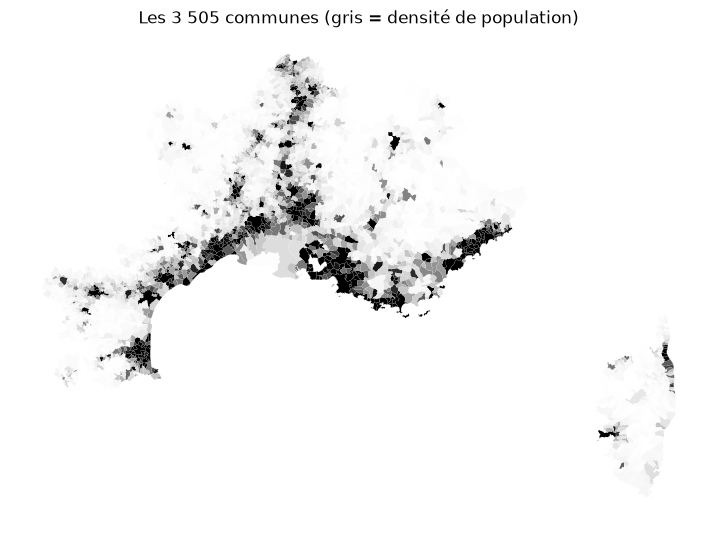

In [11]:
ax = contours.merge(communes[["code", "densite"]], on="code").plot(
    column="densite", scheme=None, cmap="Greys", vmax=300, figsize=(9, 8), linewidth=0.05, edgecolor="white")
ax.set_title("Les 3 505 communes (gris = densité de population)")
ax.set_axis_off()

## 🎯 À toi de jouer

1. Combien de communes n'ont **jamais** brûlé entre 2016 et 2025 ? (indice : `table.groupby("code", observed=True)["feu"].sum()`)
2. Quel est le taux de feu (jours avec feu / jours) en **Haute-Corse** (2B) ?

In [12]:
# à toi

<details><summary>Correction</summary>

```python
par_commune = table.groupby("code", observed=True)["feu"].sum()
(par_commune == 0).sum()            # 918 communes jamais touchées

codes_2B = communes.loc[communes["dept"] == "2B", "code"]
table[table["code"].isin(codes_2B)]["feu"].mean()
```
</details>

## Récap

1. 3 505 communes récupérées avec leur **population**, **surface** et **contour simplifié**.
2. Les feux des communes fusionnées sont rattachés à leur **commune nouvelle** (99,86 % des feux conservés).
3. Table commune × jour : **12,8 millions de lignes**, taux de feu ≈ 0,11 %.
4. Deux réflexes « gros volume » : le type **`category`** et le format **Parquet**.

**Prochaine étape (03) :** la météo SIM2 de Météo-France.